# Full-Trace Analysis — PTE (Recomputed, batch_001_en)

This notebook analyzes only `core_power.throttle` (PTE), using five features:
**mean rate, variance, spectral entropy, slope, and PTE counts per cycle**.
Each observation is one complete 20-prompt continuous trace.

Inputs are the 20 emotional and 20 neutral recordings in
`data/features/recomputed/fulltrace/batch_001_en/`.
The statistical tests, distance calculations, and plotting methods match
`fulltrace_analysis_legacy.ipynb`, applied to all five features. These inputs use the recomputed
feature definitions; keep them separate from legacy feature tables.

**PTE counts per cycle** is `sum(PTE counts) / sum(cycle counts)` for each
whole trace. Since both rates use the same duration, this equals
`core_power.throttle__mean_rate / cycles__mean_rate`.

The comparisons below are descriptive and exploratory. They do not adjust for
repeated nodes or recording dates; see `fulltrace_node_day_EN.ipynb` for the
separate node/date investigation using recomputed features.

In [1]:
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu, ttest_ind

# ── Configuration ──────────────────────────────────────────────────────────
BASE_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents]
                if (p / 'data' / 'features' / 'recomputed' / 'fulltrace').is_dir())
DATA_DIR  = BASE_DIR / 'data' / 'features' / 'recomputed' / 'fulltrace' / 'batch_001_en'

RATIO_FEATURE = 'core_power.throttle__per_cycle'
FEATURES = [
    'core_power.throttle__mean_rate',
    'core_power.throttle__variance',
    'core_power.throttle__spectral_entropy',
    'core_power.throttle__slope',
    RATIO_FEATURE,
]

SHORT = {f: f.split('__')[-1] for f in FEATURES}
SHORT[RATIO_FEATURE] = 'PTE / cycles'

SEED = 42

print('Configuration OK')
CONDITIONS = ['emotional', 'neutral']
PAIRS = list(combinations(CONDITIONS, 2))
CODES = {'emotional': 'E', 'neutral': 'N'}
COLORS = {'emotional': '#333333', 'neutral': '#999999'}

Configuration OK


## 1. Load the PTE data

In [2]:
# Load all *_whole.csv files from the fulltrace directory
whole_csvs = sorted(p for p in DATA_DIR.glob('*_whole.csv') if p.name != 'all_whole.csv')


dfs = [pd.read_csv(p) for p in whole_csvs]
df = pd.concat(dfs, ignore_index=True)

if 'condition' not in df.columns and 'label' in df.columns:
    df['condition'] = df['label']

# Exclude runsNEW neutral traces (xxx_N_x), regardless of their CSV condition label.
is_runsnew_neutral = df['run_label'].astype('string').str.fullmatch(r'[^_]+_N_[^_]+', na=False)
df = df.loc[df['condition'].isin(CONDITIONS) & ~is_runsnew_neutral].copy()

# Deduplicate on run_label — keep first occurrence
dropped = df[df.duplicated(subset='run_label', keep='first')]['run_label'].tolist()
df = df.drop_duplicates(subset='run_label', keep='first').reset_index(drop=True)
if dropped:
    print(f'\nDropped {len(dropped)} duplicate run_labels: {dropped}')

n_e = (df.condition == 'emotional').sum()
n_n = (df.condition == 'neutral').sum()
print(df['condition'].value_counts().reindex(CONDITIONS, fill_value=0))
missing = [c for c in CONDITIONS if not (df.condition == c).any()]
if missing:
    raise ValueError(f'Missing conditions: {missing}. Extract their whole-trace CSVs first.')


# Total PTE counts / total cycle counts. The common trace duration cancels.
rate_columns = ['core_power.throttle__mean_rate', 'cycles__mean_rate']
missing_rates = [column for column in rate_columns if column not in df]
if missing_rates:
    raise ValueError(f'Missing inputs for PTE / cycles: {missing_rates}')
rates = df[rate_columns].to_numpy(dtype=float)
if (not np.isfinite(rates).all() or (rates[:, 0] < 0).any()
        or (rates[:, 1] <= 0).any()):
    raise ValueError('PTE / cycles requires finite nonnegative PTE rates and positive cycle rates.')
df[RATIO_FEATURE] = rates[:, 0] / rates[:, 1]

available = []
for f in FEATURES:
    ok = f in df.columns
    print(f'  {"✓" if ok else "✗"} {SHORT[f]}')
    if ok:
        available.append(f)
FEATURES = available

print('\nData loaded successfully')

condition
emotional    20
neutral      20
Name: count, dtype: int64
  ✓ mean_rate
  ✓ variance
  ✓ spectral_entropy
  ✓ slope
  ✓ PTE / cycles

Data loaded successfully


## 2. Compare PTE features between conditions

For each of the five PTE features, report descriptive statistics, Welch's t-test,
Mann–Whitney U, and the existing standardized mean difference (`cohens_d`).
Bonferroni correction covers the five feature comparisons, separately for each
test family.

In [3]:
results = []
for feat in FEATURES:
    for left, right in PAIRS:
        a = df.loc[df.condition == left, feat].dropna().values
        b = df.loc[df.condition == right, feat].dropna().values
        if len(a) < 2 or len(b) < 2:
            raise ValueError(f'Need at least two values for {feat}: {left}/{right}')
        a_mean, a_std = np.mean(a), np.std(a, ddof=1)
        b_mean, b_std = np.mean(b), np.std(b, ddof=1)
        pooled_std = np.sqrt((a_std**2 + b_std**2) / 2)
        t_stat, t_p = ttest_ind(a, b, equal_var=False)
        u_stat, mwu_p = mannwhitneyu(a, b, alternative='two-sided')
        results.append(dict(
            feature=SHORT[feat], left=left, right=right,
            pair=f'{CODES[left]}–{CODES[right]}',
            direction='↑' + CODES[left if a_mean > b_mean else right],
            left_mean=a_mean, left_std=a_std, right_mean=b_mean, right_std=b_std,
            cohens_d=abs(a_mean-b_mean)/pooled_std if pooled_std > 0 else np.nan,
            t_stat=t_stat, t_p=t_p, U=u_stat, mwu_p=mwu_p))
res_df = pd.DataFrame(results)
n_tests = len(results)
res_df['t_p_corr'] = (res_df['t_p'] * n_tests).clip(upper=1.0)
res_df['mwu_p_corr'] = (res_df['mwu_p'] * n_tests).clip(upper=1.0)
print(f'Per-feature tests (n_E={n_e}, n_N={n_n}, Bonferroni k={n_tests})')
print(res_df.to_string(index=False))

Per-feature tests (n_E=20, n_N=20, Bonferroni k=5)
         feature      left   right pair direction    left_mean     left_std   right_mean    right_std  cohens_d    t_stat      t_p     U    mwu_p  t_p_corr  mwu_p_corr
       mean_rate emotional neutral  E–N        ↑E 1.178117e+09 5.580286e+07 1.138559e+09 6.541990e+07  0.650610  2.057410 0.046731 299.0 0.007712  0.233653    0.038559
        variance emotional neutral  E–N        ↑E 3.709028e+13 8.520665e+12 3.616646e+13 8.533050e+12  0.108342  0.342608 0.733781 210.0 0.797197  1.000000    1.000000
spectral_entropy emotional neutral  E–N        ↑E 9.187168e-01 1.859499e-02 9.054834e-01 2.397043e-02  0.616891  1.950780 0.058947 264.0 0.085855  0.294737    0.429274
           slope emotional neutral  E–N        ↑N 1.174874e+01 4.565787e+00 1.222694e+01 6.923071e+00  0.081548 -0.257877 0.798108 216.0 0.675014  1.000000    1.000000
    PTE / cycles emotional neutral  E–N        ↑E 9.183694e-03 2.995819e-04 8.743935e-03 5.593282e-04  0.9801

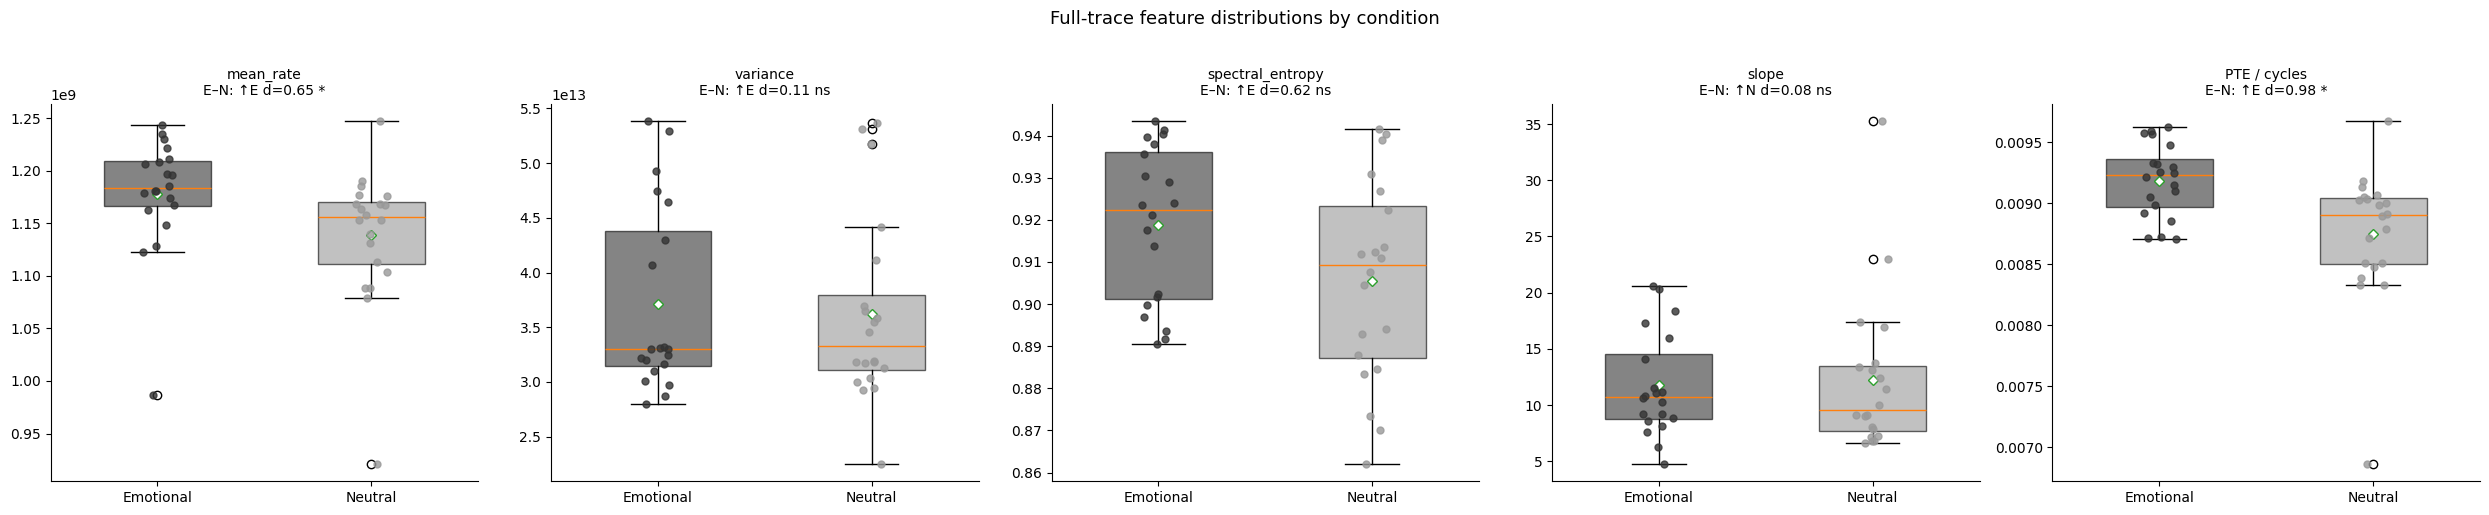

In [4]:
n_feat = len(FEATURES)
fig, axes = plt.subplots(1, n_feat, figsize=(5 * n_feat, 5), squeeze=False)
rng_j = np.random.default_rng(SEED)
for ax, feat in zip(axes[0], FEATURES):
    groups = [df.loc[df.condition == c, feat].dropna().values for c in CONDITIONS]
    positions = np.arange(len(CONDITIONS))
    bp = ax.boxplot(groups, positions=positions, widths=0.5, patch_artist=True,
                    showmeans=True, meanprops=dict(marker='D', markerfacecolor='white', markersize=5))
    for pos, cond, vals, box in zip(positions, CONDITIONS, groups, bp['boxes']):
        box.set_facecolor(COLORS[cond])
        box.set_alpha(0.6)
        ax.scatter(pos + rng_j.uniform(-0.08, 0.08, len(vals)), vals,
                   color=COLORS[cond], s=25, zorder=5, alpha=0.8)
    annotations = []
    for _, r in res_df[res_df.feature == SHORT[feat]].iterrows():
        sig = '***' if r.mwu_p_corr < 0.001 else '**' if r.mwu_p_corr < 0.01 else '*' if r.mwu_p_corr < 0.05 else 'ns'
        annotations.append(f'{r.pair}: {r.direction} d={r.cohens_d:.2f} {sig}')
    ax.set_title(SHORT[feat] + '\n' + '\n'.join(annotations), fontsize=10)
    ax.set_xticks(positions)
    ax.set_xticklabels([c.title() for c in CONDITIONS])
    ax.spines[['top', 'right']].set_visible(False)
fig.suptitle('Full-trace feature distributions by condition', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

## 3. Within-condition and cross-condition PTE distances

Compare average absolute feature differences within emotional recordings,
within neutral recordings, and across the two conditions. The inter/intra ratio
is descriptive; it is not a significance test.

In [5]:
dist_1d_results = []
for feat in FEATURES:
    for left, right in PAIRS:
        a = df.loc[df.condition == left, feat].dropna().values
        b = df.loc[df.condition == right, feat].dropna().values
        intra_a = np.array([abs(x-y) for x, y in combinations(a, 2)])
        intra_b = np.array([abs(x-y) for x, y in combinations(b, 2)])
        inter = np.abs(a[:, None] - b[None, :]).ravel()
        mean_intra = np.concatenate([intra_a, intra_b]).mean()
        r = res_df[(res_df.feature == SHORT[feat]) & (res_df.left == left) & (res_df.right == right)].iloc[0]
        dist_1d_results.append(dict(
            feature=SHORT[feat], left=left, right=right, pair=r.pair, direction=r.direction,
            intra_left=intra_a.mean(), intra_right=intra_b.mean(),
            intra_avg=mean_intra, inter=inter.mean(),
            ratio=inter.mean()/mean_intra if mean_intra > 0 else np.nan))
dist_1d_df = pd.DataFrame(dist_1d_results)
print(dist_1d_df.to_string(index=False))
print('Inter/Intra > 1: cross-condition pairs are farther apart on average.')
print('Inter/Intra ≈ 1: similar mean within- and cross-condition distances.')

         feature      left   right pair direction   intra_left  intra_right    intra_avg        inter    ratio
       mean_rate emotional neutral  E–N        ↑E 5.548578e+07 6.531123e+07 6.039851e+07 6.806691e+07 1.126964
        variance emotional neutral  E–N        ↑E 9.270381e+12 9.235180e+12 9.252780e+12 8.958595e+12 0.968206
spectral_entropy emotional neutral  E–N        ↑E 2.173670e-02 2.813269e-02 2.493470e-02 2.634401e-02 1.056520
           slope emotional neutral  E–N        ↑N 5.149549e+00 6.757011e+00 5.953280e+00 5.800967e+00 0.974415
    PTE / cycles emotional neutral  E–N        ↑E 3.510794e-04 5.554725e-04 4.532760e-04 5.566460e-04 1.228051
Inter/Intra > 1: cross-condition pairs are farther apart on average.
Inter/Intra ≈ 1: similar mean within- and cross-condition distances.


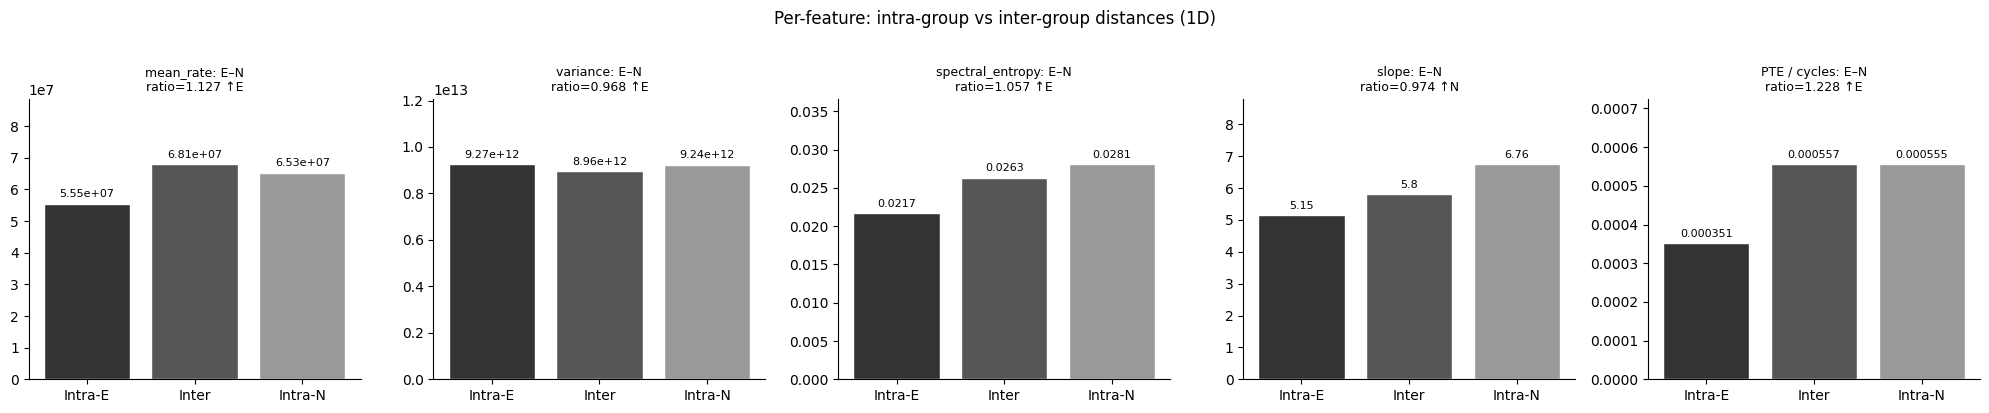

In [6]:
# Same intra/inter bars, with a row for each condition pair.
fig, axes = plt.subplots(len(PAIRS), len(FEATURES),
                         figsize=(4 * len(FEATURES), 4 * len(PAIRS)), squeeze=False)
for row_idx, (left, right) in enumerate(PAIRS):
    for col_idx, feat in enumerate(FEATURES):
        ax = axes[row_idx, col_idx]
        row = dist_1d_df[(dist_1d_df.feature == SHORT[feat]) &
                         (dist_1d_df.left == left) & (dist_1d_df.right == right)].iloc[0]
        vals = [row.intra_left, row.inter, row.intra_right]
        bars = ax.bar(range(3), vals, color=[COLORS[left], '#555555', COLORS[right]], edgecolor='white')
        for bar, val in zip(bars, vals):
            ax.text(bar.get_x()+bar.get_width()/2, val+max(vals)*0.02,
                    f'{val:.3g}', ha='center', va='bottom', fontsize=8)
        ax.set_xticks(range(3))
        ax.set_xticklabels([f'Intra-{CODES[left]}', 'Inter', f'Intra-{CODES[right]}'])
        ax.set_title(f'{row.feature}: {row.pair}\nratio={row.ratio:.3f} {row.direction}', fontsize=9)
        ax.spines[['top', 'right']].set_visible(False)
        ax.set_ylim(0, max(vals)*1.3 if max(vals) > 0 else 1)
fig.suptitle('Per-feature: intra-group vs inter-group distances (1D)', y=1.02)
plt.tight_layout()
plt.show()

## 4. PTE summary

In [7]:
print('FULL-TRACE ANALYSIS SUMMARY')
print(f'Traces: {n_e} emotional, {n_n} neutral')
print(f'Features: {len(FEATURES)}')
print('PER-FEATURE RESULTS (Bonferroni-corrected):')
print(res_df[['feature', 'pair', 'direction', 'cohens_d', 't_p_corr', 'mwu_p_corr']].to_string(index=False))
print('PER-FEATURE DISTANCE RATIOS (inter/intra):')
print(dist_1d_df[['feature', 'pair', 'ratio', 'direction']].to_string(index=False))

FULL-TRACE ANALYSIS SUMMARY
Traces: 20 emotional, 20 neutral
Features: 5
PER-FEATURE RESULTS (Bonferroni-corrected):
         feature pair direction  cohens_d  t_p_corr  mwu_p_corr
       mean_rate  E–N        ↑E  0.650610  0.233653    0.038559
        variance  E–N        ↑E  0.108342  1.000000    1.000000
spectral_entropy  E–N        ↑E  0.616891  0.294737    0.429274
           slope  E–N        ↑N  0.081548  1.000000    1.000000
    PTE / cycles  E–N        ↑E  0.980154  0.021382    0.012803
PER-FEATURE DISTANCE RATIOS (inter/intra):
         feature pair    ratio direction
       mean_rate  E–N 1.126964        ↑E
        variance  E–N 0.968206        ↑E
spectral_entropy  E–N 1.056520        ↑E
           slope  E–N 0.974415        ↑N
    PTE / cycles  E–N 1.228051        ↑E
